# A tiny stable diffusion: from a sentence to a face

> **Do the three exercises it builds on first.** This exercise puts the happy and sad faces, their extension with BERT and the text embeddings together, and its folded cells reuse their code, answers included. If you have not done them yet, do them first:
>
> https://colab.research.google.com/github/eth-bmai-hs26/w4-cx-public/blob/main/happy-sad-diffusion/happy_sad_diffusion.ipynb
>
> https://colab.research.google.com/github/eth-bmai-hs26/w4-cx-public/blob/main/happy-sad-diffusion/happy_sad_diffusion_extension.ipynb
>
> https://colab.research.google.com/github/eth-bmai-hs26/w4-cx-public/blob/main/text-embeddings/text_embeddings.ipynb

Stable Diffusion draws a picture from a sentence with two networks. A **text encoder**, the text half of CLIP, turns the sentence into numbers. A **denoiser**, the UNet of the slides, turns noise into a picture step by step and reads those numbers at every step. The text encoder is trained first, on its own, and then **frozen**: nothing in it changes any more. The denoiser then learns from pictures paired with **captions**, sentences that describe them.

This notebook builds the same two parts, tiny, out of two earlier notebooks:

* the **text embedder** of "Text embeddings from scratch": a sentence becomes three numbers, how happy, how sad and how surprised it sounds;
* the **denoiser** of the happy and sad extension: noise becomes a face of $9 \times 9$ pixels, happy, sad or surprised, and the denoiser reads three numbers at every step.

They are trained the way Stable Diffusion is: the text embedder first, on the thirty sentences, and then frozen; then the denoiser, on the faces, each with a caption of its expression. At the end you type an expression, a word like happy or a sentence like "a smiling child", and it draws the face.

**Your part: four tasks, each marked with 🎯, five lines in all.** They are the lines that turn the three notebooks into a tiny stable diffusion: the cut of the prompt in part 3, the frozen text embedder reading the thirty captions in part 4, a caption for each face in the denoiser's training in part 6, and the text embedder's step in front of the generation in part 7. Everything else is done for you. The cells that show only a title hold the code of the three earlier notebooks and draw the pictures: run them, there is nothing to change inside. Their Show code button opens one if you are curious. Run the cells from top to bottom, then try your own sentences at the end.

**Did it work?** After each task, a cell marked ✅ checks your line and prints PASS or NOT YET, with your numbers and the expected ones. After the faces of part 7 a banner says whether the whole thing works: whether the faces drawn for three words and three sentences have the expression asked for.

**Stuck?** Every task has a hint below it: click it to open it.

In [1]:
#@title Imports { display-mode: "form" }
import torch
from torch import nn
import matplotlib.pyplot as plt

In [2]:
#@title The checks of the ✅ cells { display-mode: "form" }
from IPython.display import HTML, display


def shown(values):
    # Numbers to four decimals, anything else as Python writes it.
    return [round(v, 4) if isinstance(v, float) else v for v in values]


def check(what, yours, expected):
    # PASS when yours is the expected number, or the expected numbers, to four decimals; NOT YET otherwise.
    mine = list(yours) if isinstance(yours, (tuple, list)) else [yours]
    goal = list(expected) if isinstance(expected, (tuple, list)) else [expected]
    same = len(mine) == len(goal) and all(isinstance(m, (int, float)) and abs(m - g) < 0.00005
                                          for m, g in zip(mine, goal))
    if same:
        print(f"PASS     {what}")
    else:
        print(f"NOT YET  {what}")
        print(f"         yours:    {shown(mine)}")
        print(f"         expected: {shown(goal)}")


def check_that(what, holds, otherwise):
    # PASS when it holds, NOT YET with the reason otherwise.
    if holds:
        print(f"PASS     {what}")
    else:
        print(f"NOT YET  {what}")
        print(f"         {otherwise}")


def banner(worked, headline, detail):
    # The verdict in large letters: a blue tick when it worked, a vermillion cross when not.
    colour, mark, ground = ("#0072B2", "&#10003;", "#E6F0F7") if worked else ("#D55E00", "&#10007;", "#FBEAE1")
    display(HTML(
        f'<div style="border-left: 10px solid {colour}; background: {ground}; color: #212121; '
        f'padding: 14px 20px; margin: 4px 0 14px 0; font-family: sans-serif;">'
        f'<div style="font-size: 26px; font-weight: bold; color: {colour};">{mark} {headline}</div>'
        f'<div style="font-size: 16px; margin-top: 8px;">{detail}</div></div>'))

## 1. The faces

The faces of the happy and sad extension: two eyes and a mouth that curves up (happy), curves down (sad) or is wide open (surprised), each one pixel higher or lower and one pixel further left or right, $9$ faces per expression, $27$ in all.

In [3]:
#@title The 27 faces { display-mode: "form" }
EYES = [(2, 3), (2, 5)]                                          # (row, column) of every ink pixel
HAPPY = [(5, 2), (6, 3), (6, 4), (6, 5), (5, 6)]                 # the mouth curves up
SAD = [(6, 2), (5, 3), (5, 4), (5, 5), (6, 6)]                   # the mouth curves down
SURPRISED = [(5, 3), (5, 4), (5, 5), (6, 3), (6, 5), (7, 3), (7, 4), (7, 5)]   # the mouth is wide open
EXPRESSIONS = ["happy", "sad", "surprised"]

faces, expressions = [], []
for expression, mouth in [(0, HAPPY), (1, SAD), (2, SURPRISED)]:
    for dy in [-1, 0, 1]:                                        # one pixel up, none, one pixel down
        for dx in [-1, 0, 1]:                                    # one pixel left, none, one pixel right
            face = torch.zeros(9, 9)
            for row, col in EYES + mouth:
                face[row + dy, col + dx] = 1.0
            faces.append(face.flatten())                         # the 81 pixels in one row
            expressions.append(expression)
faces = torch.stack(faces)                                       # 27 faces, 81 numbers each
expressions = torch.tensor(expressions)                          # their expressions: 0 happy, 1 sad, 2 surprised
print(faces.shape, expressions.shape)

torch.Size([27, 81]) torch.Size([27])


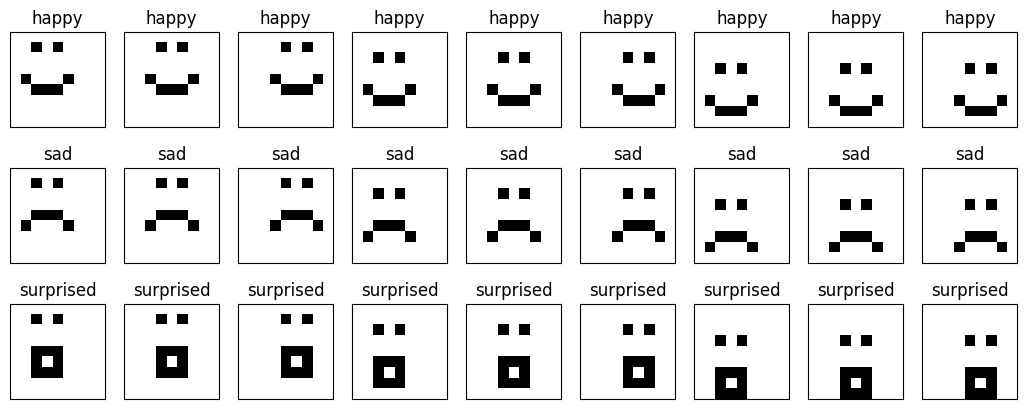

In [4]:
#@title Picture of the 27 faces { display-mode: "form" }
def show(ax, picture, title=""):
    ax.imshow(picture.reshape(9, 9), cmap="Greys", vmin=0, vmax=1)
    ax.set(xticks=[], yticks=[], title=title)


fig, axes = plt.subplots(3, 9, figsize=(13, 5))
for ax, face, expression in zip(axes.flat, faces, expressions):
    show(ax, face, EXPRESSIONS[expression])
plt.show()

## 2. The captions

The thirty short descriptions of the extension, ten for each expression. They are the **captions**: when the denoiser learns from a happy face, it gets one of the ten happy sentences with it. The **vocabulary** is the list of their different words, as in the text embeddings notebook.

In [5]:
HAPPY_TEXTS = ["a happy face", "a smiling face", "someone who is glad", "a cheerful person", "she is delighted",
               "he is laughing", "a big smile", "a pleased child", "they look very happy", "a grinning man"]
SAD_TEXTS = ["a sad face", "an unhappy face", "someone who is crying", "a gloomy person", "she is upset",
             "he is miserable", "tears running down a face", "a heartbroken child", "they look very sad",
             "a tearful woman"]
SURPRISED_TEXTS = ["a surprised face", "an astonished face", "someone who is amazed", "a shocked person",
                   "she is stunned", "he is startled", "a mouth wide open in surprise", "a speechless child",
                   "they look very surprised", "an open-mouthed man"]

sentences = HAPPY_TEXTS + SAD_TEXTS + SURPRISED_TEXTS            # 30 captions: 0 to 9 happy, 10 to 19 sad, 20 to 29 surprised
labels = torch.tensor([0] * 10 + [1] * 10 + [2] * 10)            # their expressions: 0 happy, 1 sad, 2 surprised
vocabulary = sorted(set(" ".join(sentences).split()))            # every different word, once
print(len(sentences), "captions,", len(vocabulary), "words:", vocabulary)

30 captions, 49 words: ['a', 'amazed', 'an', 'astonished', 'big', 'cheerful', 'child', 'crying', 'delighted', 'down', 'face', 'glad', 'gloomy', 'grinning', 'happy', 'he', 'heartbroken', 'in', 'is', 'laughing', 'look', 'man', 'miserable', 'mouth', 'open', 'open-mouthed', 'person', 'pleased', 'running', 'sad', 'she', 'shocked', 'smile', 'smiling', 'someone', 'speechless', 'startled', 'stunned', 'surprise', 'surprised', 'tearful', 'tears', 'they', 'unhappy', 'upset', 'very', 'who', 'wide', 'woman']


## 3. The text embedder

The model of the text embeddings notebook. Every word has two numbers of its own in a table, `three_numbers` averages the rows of a sentence's words, and a wide network turns the average into three numbers, trained towards the one-hot of the sentence's expression: $[1, 0, 0]$ for happy, $[0, 1, 0]$ for sad, $[0, 0, 1]$ for surprised.

In [6]:
#@title The text embedder, as in the text embeddings notebook { display-mode: "form" }
torch.manual_seed(0)   # seeded: the same starting numbers on every computer

embedding = nn.Embedding(len(vocabulary), 2)                     # a table: 2 numbers for every word
nn.init.normal_(embedding.weight, std=0.02)                      # every word starts close to (0, 0)

network = nn.Sequential(
    nn.Linear(2, 100), nn.ReLU(),                                # wide: one hidden layer of 100 neurons
    nn.Linear(100, 3),                                           # out: the 3 numbers of the sentence
)


def three_numbers(sentence):
    ids = torch.tensor([vocabulary.index(word) for word in sentence.split()])   # the number of every word
    vectors = embedding(ids)                                     # its row of the table: 2 numbers per word
    average = vectors.mean(dim=0)                                # their average: 2 numbers for the sentence
    return network(average)                                      # 3 numbers for the sentence

`prompt_from(sentence)` is what the denoiser will read, the **prompt**: the three numbers of the sentence, each cut to between $0$ and $1$. The cut matters for a single word: "happy" alone has no other word to average with, so its numbers come out larger than any caption's, about $2$ for happy, and the denoiser has never seen such a prompt. Words that are not in the vocabulary are left out, and a sentence with no word the embedder knows gets the empty prompt $[0, 0, 0]$.

🎯 **Task 1.** Complete `prompt_from`: its last line returns the three numbers of the sentence, `numbers`, each cut to between $0$ and $1$.

<details>
<summary><b>Hint for task 1</b> (click to open)</summary>

A tensor's `.clamp(low, high)` cuts every number of it to between `low` and `high`: a number below `low` becomes `low`, one above `high` becomes `high`, and the others stay as they are. Here the tensor is `numbers`, `low` is $0$ and `high` is $1$.

</details>

In [7]:
# ============================================================
# 🎯 TASK 1: the cut of the prompt, in prompt_from
# ============================================================
def prompt_from(sentence):
    known = [word for word in sentence.lower().split() if word in vocabulary]   # words it never saw are left out
    if not known:
        return torch.zeros(3)                                    # no word it knows: the empty prompt
    with torch.no_grad():                                        # the text embedder is only read here
        numbers = three_numbers(" ".join(known))                 # the 3 numbers of the sentence
    # 🎯 COMPLETE THIS LINE: each of the 3 numbers cut to between 0 and 1
    return numbers.clamp(0, 1)

In [10]:
#@title ✅ Check task 1 { display-mode: "form" }
for sentence in ["happy", "a happy face", "someone who is crying"]:
    with torch.no_grad():
        raw = three_numbers(sentence).tolist()                   # its 3 numbers before the cut
    l = prompt_from(sentence).tolist()
    check(f'"{sentence}": its 3 numbers, each cut to between 0 and 1', l,
          [min(max(v, 0.0), 1.0) for v in raw])
    print(prompt_from(sentence))
check("a sentence with no word it knows: the empty prompt", prompt_from("good morning").tolist(), [0.0, 0.0, 0.0])

PASS     "happy": its 3 numbers, each cut to between 0 and 1
tensor([0.1670, 0.2622, 0.0075])
PASS     "a happy face": its 3 numbers, each cut to between 0 and 1
tensor([0.1673, 0.2630, 0.0097])
PASS     "someone who is crying": its 3 numbers, each cut to between 0 and 1
tensor([0.1674, 0.2630, 0.0109])
PASS     a sentence with no word it knows: the empty prompt


## 4. Training the text embedder, then freezing it

The loop of the text embeddings notebook: the average squared difference between the three numbers of the thirty sentences and their one-hots, until it is below $0.01$. It takes a few dozen steps.

In [11]:
#@title Training the text embedder, as in the text embeddings notebook { display-mode: "form" }
targets = torch.eye(3)[labels]                                   # the one-hot of every sentence's expression
optimizer = torch.optim.Adam(list(embedding.parameters()) + list(network.parameters()), lr=0.01)

loss = 1.0                                                       # any start above the threshold
while loss > 0.01:
    numbers = torch.stack([three_numbers(sentence) for sentence in sentences])   # 30 sentences, 3 numbers each
    loss = ((numbers - targets) ** 2).mean()                     # the average squared difference
    optimizer.zero_grad()                                        # forget the gradients of the previous step
    loss.backward()                                              # compute the gradient of the loss
    optimizer.step()                                             # move every weight, and every word, a small step
    print(f"\rloss: {loss.item():.4f}", end="")

loss: 0.0098

Then the text embedder reads the thirty captions once, and from here on it is **frozen**: the denoiser's training reads these thirty prompts and never changes the table or the wide network, as Stable Diffusion's denoiser reads CLIP.

🎯 **Task 2.** Write `caption_prompts`: the prompt of each of the thirty captions, read with `prompt_from`, stacked into one tensor of $30$ rows of $3$ numbers, in the order of `sentences`.

<details>
<summary><b>Hint for task 2</b> (click to open)</summary>

The text embeddings notebook computes the three numbers of all thirty sentences in its training loop with `torch.stack([three_numbers(sentence) for sentence in sentences])`. Here, the same with `prompt_from`.

</details>

In [12]:
# ============================================================
# 🎯 TASK 2: the prompts of the 30 captions
# ============================================================
# 🎯 COMPLETE THIS LINE: the prompts of the 30 captions, 30 rows of 3 numbers
caption_prompts = torch.stack([prompt_from(sentence) for sentence in sentences])
for i in [0, 10, 20]:
    print(f"{sentences[i]!r:20} prompt {caption_prompts[i].numpy().round(2)}")

'a happy face'       prompt [1. 0. 0.]
'a sad face'         prompt [0.01 1.   0.  ]
'a surprised face'   prompt [0. 0. 1.]


In [13]:
#@title ✅ Check task 2 { display-mode: "form" }
check_that("30 prompts of 3 numbers", tuple(caption_prompts.shape) == (30, 3),
           f"caption_prompts has the shape {tuple(caption_prompts.shape)}")
if tuple(caption_prompts.shape) == (30, 3):
    for i in [0, 15, 29]:
        check(f'caption {i}, "{sentences[i]}": the prompt prompt_from reads', caption_prompts[i].tolist(),
              prompt_from(sentences[i]).tolist())

PASS     30 prompts of 3 numbers
PASS     caption 0, "a happy face": the prompt prompt_from reads
PASS     caption 15, "he is miserable": the prompt prompt_from reads
PASS     caption 29, "an open-mouthed man": the prompt prompt_from reads


## 5. The denoiser

The denoiser of the happy and sad extension, unchanged. The forward process fades a face into one noise picture over $T = 20$ steps. The network reads $81 + 1 + 3 = 85$ numbers, the noisy picture, the step $t$ (as $t/T$) and the prompt, and guesses the clean face; `previous_picture` moves the picture a $1/t$ part of the way towards that guess, which is its estimate of the picture one step earlier.

In [14]:
#@title The denoiser, as in the happy and sad extension { display-mode: "form" }
T = 20                                                           # the number of steps from a face to pure noise


def add_noise(face, noise, t):
    return (1 - t / T) * face + (t / T) * noise                 # the picture at step t


torch.manual_seed(0)   # seeded again: the denoiser starts the same whatever the text embedder did
net = nn.Sequential(
    nn.Linear(81 + 1 + 3, 128), nn.ReLU(),                       # in: the noisy picture, the step and the prompt
    nn.Linear(128, 128), nn.ReLU(),
    nn.Linear(128, 81),                                          # out: its guess of the clean face
)


def previous_picture(x, t, prompt):
    guess = net(torch.cat([x, t / T, prompt], dim=1))            # the network's guess of the clean face
    return x + (guess - x) / t                                   # one step from x_t towards it: the estimate of x_{t-1}

## 6. Training the denoiser on faces with their captions

The loop of the happy and sad notebook, with one change: the prompt of each face is a **caption**. Every step picks $256$ faces at random and, for each face, one of the ten captions of its expression, also at random; the face's prompt is that caption's three numbers, read from the frozen text embedder. Only the denoiser learns here. The loop stops at the threshold of the happy and sad notebook, after a few thousand steps.

🎯 **Task 3.** In the loop, each of the $256$ faces of a step needs a caption of its own expression, at random. Captions $0$ to $9$ are happy, $10$ to $19$ sad and $20$ to $29$ surprised, so the captions of expression $k$ are $10k$ to $10k + 9$. Write `caption`, the number of a random caption of each face's expression, and `prompt`, the rows of `caption_prompts` of those captions.

<details>
<summary><b>Hint for task 3</b> (click to open)</summary>

`expressions[pick]` is the expression of each of the $256$ faces, so `10 * expressions[pick]` is the first caption of each one's expression. `torch.randint(0, 10, (256,))` is a whole number from $0$ to $9$ for each face, at random: add the two. Then `caption_prompts[caption]` picks the rows of those captions, one row of $3$ numbers for each face.

</details>

The loop stops after a few thousand steps, about $20$ seconds on Colab. If the loss printed under the cell is still above $0.05$ after a minute, stop the cell with the square button next to it and check your lines.

In [19]:
# ============================================================
# 🎯 TASK 3: a caption for each face, in the loop below
# ============================================================
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)        # only the denoiser's weights: the text embedder is frozen

loss = 1.0                                                       # any start above the threshold
while loss > 0.012:
    pick = torch.randint(0, 27, (256,))                          # 256 faces picked at random
    face = faces[pick]
    # 🎯 COMPLETE THESE TWO LINES: a caption of its own expression for each face, and its prompt
    exp = expressions[pick] * 10
    caption = exp + torch.randint(0, 10, (256,))
    prompt = caption_prompts[caption]
    noise = torch.randn_like(face)                               # a noise picture for each face
    t = torch.randint(1, T + 1, (256, 1)).float()                # a step between 1 and T for each face
    x_t = add_noise(face, noise, t)                              # the noisy picture at step t
    x_previous = add_noise(face, noise, t - 1)                   # the true picture one step earlier
    loss = ((previous_picture(x_t, t, prompt) - x_previous) ** 2).sum(dim=1).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f"\rloss: {loss.item():.4f}", end="")

loss: 0.0119

In [20]:
#@title ✅ Check task 3 { display-mode: "form" }
# What the last step of the loop picked: 256 faces, and a caption and a prompt for each.
check_that("one caption for each of the 256 faces", tuple(caption.shape) == (256,),
           f"caption has the shape {tuple(caption.shape)}")
inside = tuple(caption.shape) == (256,) and bool(((caption >= 0) & (caption <= 29)).all())
check_that("every caption is a number from 0 to 29", inside, f"caption holds {caption.min().item()} to {caption.max().item()}")
if inside:
    caption = caption.long()
    check("every caption describes the expression of its face", int((labels[caption] == expressions[pick]).sum()), 256)
    check_that("the captions are picked at random among the 10 of each expression", len(set(caption.tolist())) > 15,
               f"only {len(set(caption.tolist()))} different captions among 256")
    check_that("each face's prompt is its caption's 3 numbers",
               tuple(prompt.shape) == (256, 3) and torch.equal(prompt, caption_prompts.index_select(0, caption)),
               "prompt is not the rows of caption_prompts of those captions")
check_that("the loop stopped by itself: the loss is below 0.012", loss.item() < 0.012, f"the loss is {loss.item():.4f}")

PASS     one caption for each of the 256 faces
PASS     every caption is a number from 0 to 29
PASS     every caption describes the expression of its face
PASS     the captions are picked at random among the 10 of each expression
PASS     each face's prompt is its caption's 3 numbers
PASS     the loop stopped by itself: the loss is below 0.012


## 7. From a sentence to a face

The three steps of the slides, with one step in front of them: the frozen text embedder turns the sentence into its prompt. The denoiser then reads that prompt at every step, from noise down to the face.

🎯 **Task 4.** Complete `faces_from`. Its first line is Stable Diffusion's first step: the frozen text embedder reads the sentence. Write `prompt`, the prompt of `sentence`.

<details>
<summary><b>Hint for task 4</b> (click to open)</summary>

One call of `prompt_from`, the function of part 3, on `sentence`.

</details>

In [21]:
# ============================================================
# 🎯 TASK 4: the text embedder's step, in faces_from
# ============================================================
def faces_from(sentence, how_many=8):
    # 🎯 COMPLETE THIS LINE: the frozen text embedder reads the sentence
    prompt = prompt_from(sentence)
    with torch.no_grad():
        x = torch.randn(how_many, 81)                            # 1) sample noise: x_T
        prompts = prompt.repeat(how_many, 1)                     # the same prompt for every face
        t = T
        while t > 0:                                             # 2) for t = T, T-1, ..., 1:
            step = torch.full((how_many, 1), float(t))
            x = previous_picture(x, step, prompts)               #    estimate x_{t-1} from x_t
            t = t - 1
    return x, prompt                                             # 3) output x_0, with the prompt it read

In [22]:
#@title ✅ Check task 4 { display-mode: "form" }
for sentence in ["happy", "he is upset"]:
    pictures, read = faces_from(sentence, how_many=2)
    check(f'"{sentence}": the prompt the frozen text embedder reads', read.tolist(), prompt_from(sentence).tolist())
check_that("two faces of 81 pixels when asked for two", tuple(pictures.shape) == (2, 81),
           f"the faces have the shape {tuple(pictures.shape)}")

PASS     "happy": the prompt the frozen text embedder reads
PASS     "he is upset": the prompt the frozen text embedder reads
PASS     two faces of 81 pixels when asked for two


Eight faces for each of six prompts: the three expressions as single words, then three sentences that are not among the captions, made of words the text embedder knows.

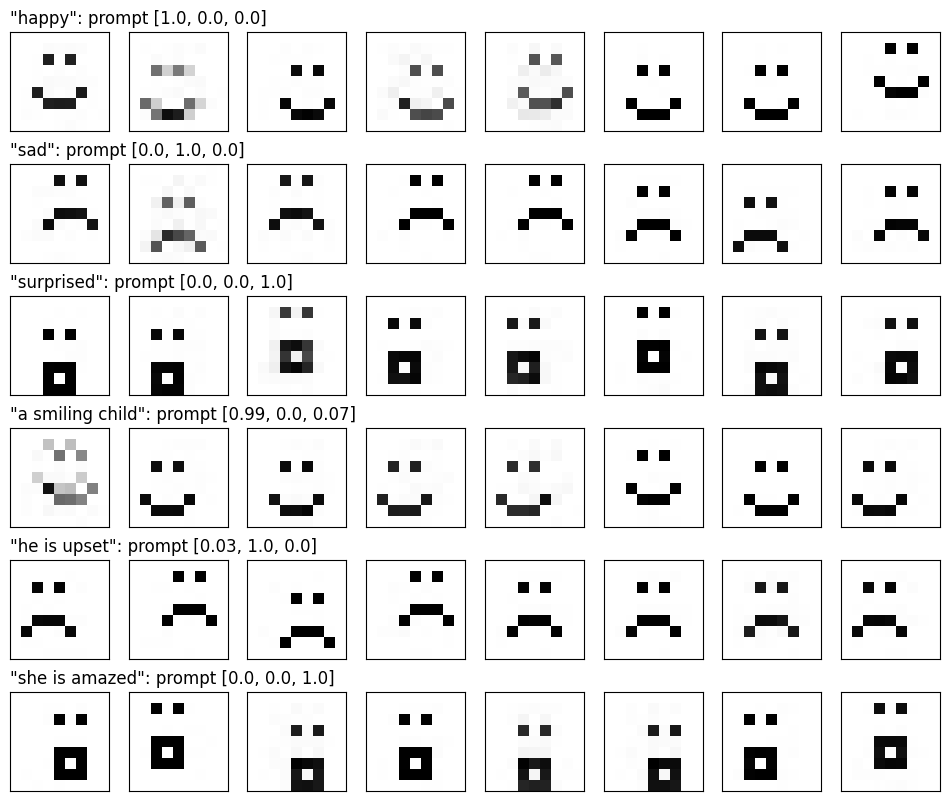

In [23]:
#@title Faces for six prompts { display-mode: "form" }
examples = ["happy", "sad", "surprised", "a smiling child", "he is upset", "she is amazed"]
fig, axes = plt.subplots(len(examples), 8, figsize=(12, 10))
for row, sentence in zip(axes, examples):
    pictures, prompt = faces_from(sentence)
    for ax, picture in zip(row, pictures):
        show(ax, picture)
    row[0].set_title(f'"{sentence}": prompt {[round(v, 2) for v in prompt.tolist()]}', loc="left")
plt.show()

In [24]:
#@title Does it draw the face a word or a sentence asks for? { display-mode: "form" }
asked = [("happy", 0), ("sad", 1), ("surprised", 2), ("a smiling child", 0), ("he is upset", 1), ("she is amazed", 2)]
right = 0
for sentence, k in asked:
    pictures, read = faces_from(sentence, how_many=10)
    nearest = (pictures[:, None, :] - faces[None, :, :]).abs().mean(dim=2).argmin(dim=1)   # the nearest of the 27 faces
    right += int((expressions[nearest] == k).sum())
told = (f"Of 60 faces drawn for happy, sad, surprised, a smiling child, he is upset and she is amazed, {right} "
        "have the expression asked for.")
if right >= 57:
    banner(True, "Your tiny stable diffusion draws the face a sentence asks for", told)
else:
    banner(False, "Not yet", told + " The checks above show which line is not right yet.")

## 8. Try it

* Write your own sentence in the cell below and run it. The cell prints the prompt and the words the text embedder never saw.
* What prompt does "a smiling and crying face" get, and which faces does the denoiser draw from it?
* "tears of joy" and "a face that is not happy": which words does the text embedder read, and which face comes out?
* Compare "a smiling man" and "a smiling woman". The only caption with the word woman is "a tearful woman": what does that do to the faces?
* "good morning" has no word the text embedder knows, so the denoiser gets the empty prompt $[0, 0, 0]$, which it never saw in training. What does it draw?

prompt: [0.98 0.03 0.  ]   never saw: []


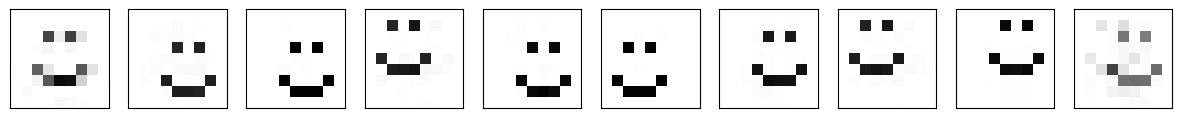

In [25]:
sentence = "a cheerful child"                                    # write your own sentence here
pictures, prompt = faces_from(sentence, how_many=10)
print("prompt:", prompt.numpy().round(2), "  never saw:", [w for w in sentence.lower().split() if w not in vocabulary])
fig, axes = plt.subplots(1, 10, figsize=(15, 1.9))
for ax, picture in zip(axes, pictures):
    show(ax, picture)
plt.show()

## 9. What Stable Diffusion does differently

The same two parts and the same training, at a much larger scale.

* Its text encoder is the text half of CLIP, a transformer trained on $400$ million pictures with their captions. It gives $768$ numbers for each of up to $77$ tokens of the prompt, where ours gives three numbers for the whole sentence.
* Its denoiser, a UNet, reads those numbers through cross-attention, the attention of weekend 2, at every step; ours glues the three numbers to the noisy picture.
* It draws in the code of an autoencoder, a variational one as this morning: $64 \times 64 \times 4$ numbers for a picture of $512 \times 512$ pixels, which the decoder turns into the picture at the end. Ours draws the $81$ pixels themselves.
* Its denoiser guesses the noise, as on the slides; ours guesses the clean face, as in the happy and sad notebook.